# 10 — Roofline: where each backend sits on the Xeon Max socket

**Objective.** Place every measured serving point of both backends against the limits of the hardware it ran on —
one Xeon Max 9480 socket (55 compute cores) with HBM in cache mode — and see how the points move as concurrency and
context length grow.

**Research question.** For each configuration, which serving regimes are memory-bound and which are compute-bound;
how close does each backend get to the roof that bounds it; and does concurrency or context length move it from one
side of the ridge to the other?

**Data.**
- `online_points` (notebook 04–07): steady-window token rates and the server's measured memory traffic (core PMU,
  reads + writes beyond L3, validated against STREAM in notebook 01).
- `stream_calibration` (Experiment 0): STREAM triad on the server layout under the same counters, 4–96 GiB working
  sets — the **memory roofs**.
- `hardware_ceilings` — the **compute roofs**, from two campaigns: the hardware-only roofline study (hw-bench,
  2026-09-21, a cache-mode node of the same partition: full-socket AVX-512 FMA, AMX INT8 tile peak, a oneDNN BF16
  GEMM), and a GEMM job on the server layout (`scripts/benchmark/gemm_ceilings.py`, job 5317636, 2026-10-11) that
  times BF16 and INT8 AMX GEMMs inside the vLLM image, including the kernels vLLM runs for the Llama projections.

**Method.**
- *Arithmetic rate* = modelled operations of the tokens processed per second: every prompt token through all
  projections plus causal attention, every output token through the projections, the LM head and attention over its
  context (`analysis.roofline.ops_per_request`; 2 operations per multiply-accumulate, FLOP for BF16 and integer
  operations for the INT8 weight GEMMs). The PMU offers no usable operation counter, so the arithmetic is modelled;
  section 2 checks it against the measured AMX busy cycles.
- *Operational intensity* = arithmetic rate ÷ **measured** memory traffic. Because the traffic is measured, the
  intensity includes everything the engine really moves (activations, re-reads, scheduler overhead), not an ideal
  minimum.
- *Memory roof* of a point = STREAM traffic at the point's modelled working set (weights + live KV), so a point whose
  working set no longer fits the 64 GiB HBM cache gets the lower, DDR-dominated roof.
- *Compute roof* of a configuration = the measured ceiling of the units its weight GEMMs run on: the best measured
  AMX BF16 GEMM (vLLM BF16), AVX-512 FMA (llama.cpp BF16, which has no BF16 AMX kernel), the best measured AMX INT8
  GEMM (both INT8 configurations). For vLLM a second, engine-level ceiling is shown: its own projection kernels on the
  Llama shapes, operation-weighted over the four projections.
- A point is on the *memory-bound side* when its intensity is below the ridge point (compute roof ÷ memory roof).
  *Share of a roof* = achieved ÷ roof; the larger of the two shares is the point's efficiency against the roofline.

**Limits.** Cache mode: the counters see HBM-cache hits and DDR together, so a single memory level is placed, not
HBM and DDR separately. The instruction peaks come from another node of the same partition at 56 threads (scaled to
55 cores); the AMX BF16 tile peak is derived (half the measured INT8 tile rate) and labelled so. The GEMM roofs are the
best *measured* GEMMs, not proven maxima: a better kernel could exceed them.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display

from llm_backend_analysis.analysis import memory, roofline
from llm_backend_analysis.data import loaders, registry
from llm_backend_analysis.reporting import Claim, claims_table, export_table, num, pct, rng, show, table, x
from llm_backend_analysis.visualization import plots, theme
from llm_backend_analysis.visualization.export import export_figure

theme.setup_notebook()
NOTEBOOK = "10_roofline.ipynb"
MODEL = registry.primary_model()  # Llama-3.1-8B-Instruct; the 1B model is the cross-check (section 7)

## 1. The hardware: roofs of one socket in HBM cache mode

In [2]:
hw_all = loaders.hardware_ceilings(accepted_only=False)
compute = roofline.compute_ceilings(loaders.hardware_ceilings())
mem = roofline.memory_ceilings(loaders.stream_calibration())
memory_roofs = roofline.memory_roofs(mem)
cores = registry.topology()["compute_threads"]

display(table(compute.reset_index()[["label", "basis", "tops", "tops_measured_socket", "measured_threads", "n_records",
                                     "spread_rel", "host"]]
              .rename(columns={"label": "Compute roof", "basis": "Basis", "tops": f"TOP/s, {cores} cores",
                               "tops_measured_socket": "TOP/s as measured", "measured_threads": "threads",
                               "n_records": "records", "spread_rel": "max−min ÷ median", "host": "node"}),
              {f"TOP/s, {cores} cores": "{:.1f}", "TOP/s as measured": "{:.1f}", "threads": "{:.0f}", "records": "{:.0f}",
               "max−min ÷ median": "{:.1%}"},
              caption="Compute roofs (median of the accepted full-socket hw-bench records, socket 0)"))
rej = hw_all[~hw_all["accepted"]].groupby(["kernel", "reject_reason"]).size().reset_index(name="records")
display(table(rej.rename(columns={"kernel": "Kernel", "reject_reason": "Excluded because", "records": "Records"}),
              caption="hw-bench records excluded by its own acceptance rules (kept in data/raw/hardware)"))
display(table(mem.rename(columns={"working_set_gib": "Working set (GiB)", "mem_total_gbs": "PMU traffic (GB/s)",
                                  "stream_triad_gbs": "STREAM triad (GB/s)", "fits_hbm_cache": "fits 64 GiB HBM cache"}),
              {"Working set (GiB)": "{:g}", "PMU traffic (GB/s)": "{:.0f}", "STREAM triad (GB/s)": "{:.0f}"},
              caption=f"Memory roofs: STREAM triad, {cores} threads on the server cores, same PMU counters"))

Compute roof,Basis,"TOP/s, 55 cores",TOP/s as measured,threads,records,max−min ÷ median,node
AMX INT8 tile peak,measured,214.2,218.1,56,5,0.1%,cresco8-hbm15
AMX BF16 tile peak,derived: ½ × AMX INT8 tile peak,107.1,–,–,–,–,–
AMX INT8 GEMM,"measured: best of 48 GEMM configurations (vllm_sgl_int8, 8192×28672×4096, vllm_pinned)",88.3,88.3,55,3,2.4%,cresco8-hbm01
vLLM INT8 projection kernels,"measured: vllm_sgl_int8 over the 4 projection shapes, operation-weighted (M = 8192, vllm_pinned)",68.9,–,–,–,–,–
AMX BF16 GEMM,"measured: best of 27 GEMM configurations (vllm_onednn_bf16, 2048×4096×4096, vllm_pinned)",42.5,42.5,55,3,0.2%,cresco8-hbm01
vLLM BF16 projection kernels,"measured: vllm_onednn_bf16 over the 4 projection shapes, operation-weighted (M = 2048, vllm_pinned)",23.6,–,–,–,–,–
AVX-512 FP32 FMA,measured,8.1,8.3,56,5,0.2%,cresco8-hbm15


Kernel,Excluded because,Records
amx_bf16_dot,not run on the characterized node cresco8-hbm15,10
amx_bf16_gemm,oneDNN affinity anomaly (superseded series),10
amx_int8_dot,not run on the characterized node cresco8-hbm15,10
avx512_fp32_fma,not run on the characterized node cresco8-hbm15,10
avx512_fp64_fma,not run on the characterized node cresco8-hbm15,10


Working set (GiB),PMU traffic (GB/s),STREAM triad (GB/s),fits 64 GiB HBM cache
4,502,519,True
8,496,505,True
16,479,484,True
32,382,383,True
48,301,302,True
64,252,252,False
96,191,191,False


In [3]:
gm = roofline.gemm_measurements(loaders.hardware_ceilings())
gm_best = gm.loc[gm.groupby(["kernel", "binding"])["tops"].idxmax()].sort_values(["dtype", "tops"], ascending=[True, False])
display(table(gm_best[["dtype", "kernel", "binding", "shape", "tops", "n_records", "spread_rel", "amx_confirmed", "campaign"]]
              .rename(columns={"dtype": "Type", "kernel": "Kernel", "binding": "Threads", "shape": "Best shape M×N×K",
                               "tops": f"TOP/s, {cores} cores", "n_records": "reps", "spread_rel": "max−min ÷ median",
                               "amx_confirmed": "AMX confirmed", "campaign": "campaign"}),
              {f"TOP/s, {cores} cores": "{:.1f}", "reps": "{:.0f}", "max−min ÷ median": "{:.1%}"},
              caption="Measured AMX GEMMs: best shape per kernel and thread binding (median over repetitions). "
                      "vllm_* = the kernels vLLM 0.30 runs for the Llama projections"))
arch = roofline.architecture(MODEL)
mix = pd.concat([roofline.projection_mix(gm, arch, k) for k in ("vllm_onednn_bf16", "vllm_sgl_int8")], ignore_index=True)
mix_best = mix.loc[mix.groupby("kernel")["tops"].idxmax()].set_index("kernel")
display(table(mix_best.reset_index()[["kernel", "binding", "gemm_m", "tops_qkv", "tops_o", "tops_gate_up", "tops_down", "tops"]]
              .rename(columns={"kernel": "vLLM kernel", "binding": "Threads", "gemm_m": "M", "tops_qkv": "qkv",
                               "tops_o": "o", "tops_gate_up": "gate_up", "tops_down": "down",
                               "tops": "operation-weighted"}),
              {c: "{:.1f}" for c in ["qkv", "o", "gate_up", "down", "operation-weighted"]},
              caption=f"vLLM's projection kernels on the {registry.model_label(MODEL)} shapes (TOP/s; gate_up carries "
                      f"{pct(mix_best['ops_share_gate_up'].iloc[0], signed=False)} of the projection operations)"))
hb = gm[(gm["kernel"] == "amx_bf16_gemm")]["tops"].max()
tb = gm[(gm["kernel"] == "torch_mm_bf16")]["tops"]
im = gm[gm["kernel"] == "torch_int_mm"]
show(f"The same 6144³ oneDNN BF16 GEMM measures {num(hb, 1)} TOP/s in hw-bench (one timed call per record) and "
     f"{rng(tb, lambda v: num(v, 1))} TOP/s on the server layout (median of ≥ 5 timed calls). "
     f"`torch._int_mm` ({rng(im['tops'], lambda v: num(v, 1))} TOP/s) runs through oneDNN's legacy gemm API, whose "
     "verbose output names no AMX implementation, so it is not used as a roof. "
     f"vLLM's BF16 kernel runs gate_up at {num(mix_best.loc['vllm_onednn_bf16', 'tops_gate_up'], 1)} TOP/s against "
     f"{num(compute.loc['amx_bf16_gemm', 'tops'], 1)} for its best shape, which caps its operation-weighted rate at "
     f"{num(compute.loc['vllm_bf16_kernels', 'tops'], 1)} TOP/s "
     f"({pct(compute.loc['vllm_bf16_kernels', 'tops'] / compute.loc['amx_bf16_gemm', 'tops'], signed=False)} of the BF16 GEMM roof); "
     f"vLLM's INT8 kernels reach {num(compute.loc['vllm_int8_kernels', 'tops'], 1)} TOP/s "
     f"({pct(compute.loc['vllm_int8_kernels', 'tops'] / compute.loc['amx_int8_gemm', 'tops'], signed=False)} of the INT8 GEMM roof). "
     f"Best INT8 ÷ best BF16 GEMM: {x(compute.loc['amx_int8_gemm', 'tops'] / compute.loc['amx_bf16_gemm', 'tops'], 2)} "
     "(the INT8 tile rate is 2×).")

Type,Kernel,Threads,Best shape M×N×K,"TOP/s, 55 cores",reps,max−min ÷ median,AMX confirmed,campaign
bf16,vllm_onednn_bf16,vllm_pinned,2048×4096×4096,42.5,3,0.2%,True,gemm-ceilings-20261011
bf16,vllm_onednn_bf16,mask,2048×4096×4096,39.6,3,2.1%,True,gemm-ceilings-20261011
bf16,torch_mm_bf16,vllm_pinned,6144×6144×6144,38.8,3,2.2%,True,gemm-ceilings-20261011
bf16,torch_mm_bf16,mask,6144×6144×6144,36.2,3,8.8%,True,gemm-ceilings-20261011
bf16,amx_bf16_gemm,mask,6144×6144×6144,26.7,5,10.8%,True,cache-20260921T173410Z
int8,vllm_sgl_int8,vllm_pinned,8192×28672×4096,88.3,3,2.4%,True,gemm-ceilings-20261011
int8,vllm_sgl_int8,mask,8192×28672×4096,85.4,3,4.3%,True,gemm-ceilings-20261011
int8,vllm_onednn_int8,vllm_pinned,8192×4096×14336,73.2,3,0.9%,True,gemm-ceilings-20261011
int8,vllm_onednn_int8,mask,8192×4096×14336,65.7,3,3.5%,True,gemm-ceilings-20261011
int8,torch_int_mm,mask,6144×6144×6144,43.6,3,2.3%,False,gemm-ceilings-20261011


vLLM kernel,Threads,M,qkv,o,gate_up,down,operation-weighted
vllm_onednn_bf16,vllm_pinned,2048,30.8,42.5,18.4,35.1,23.6
vllm_sgl_int8,vllm_pinned,8192,80.0,73.7,88.3,45.3,68.9


The same 6144³ oneDNN BF16 GEMM measures 26.7 TOP/s in hw-bench (one timed call per record) and 36.2–38.8 TOP/s on the server layout (median of ≥ 5 timed calls). `torch._int_mm` (43.5–43.6 TOP/s) runs through oneDNN's legacy gemm API, whose verbose output names no AMX implementation, so it is not used as a roof. vLLM's BF16 kernel runs gate_up at 18.4 TOP/s against 42.5 for its best shape, which caps its operation-weighted rate at 23.6 TOP/s (55% of the BF16 GEMM roof); vLLM's INT8 kernels reach 68.9 TOP/s (78% of the INT8 GEMM roof). Best INT8 ÷ best BF16 GEMM: 2.08× (the INT8 tile rate is 2×).

In [4]:
ridge = pd.DataFrame([{"Compute roof": compute.loc[k, "label"], "Basis": compute.loc[k, "basis"],
                       **{f"ridge at {gbs:.0f} GB/s (OP/byte)": compute.loc[k, "tops"] * 1e3 / gbs for gbs, _ in memory_roofs}}
                      for k in compute.index])
display(table(ridge, {c: "{:.0f}" for c in ridge.columns[2:]},
              caption="Ridge points: the intensity at which a compute roof meets each memory roof"))
top_gbs, big_gbs = memory_roofs[0][0], memory_roofs[1][0]
gemm = compute.loc["amx_bf16_gemm", "tops"]
show(f"The measured AMX BF16 GEMM reaches {pct(gemm / compute.loc['amx_bf16_peak', 'tops'], signed=False)} of the "
     f"AMX BF16 tile peak; the tile peak is {x(compute.loc['amx_bf16_peak', 'tops'] / compute.loc['avx512_fma', 'tops'])} "
     f"the AVX-512 FMA roof. Leaving the HBM cache lowers the memory roof from {num(top_gbs)} to {num(big_gbs)} GB/s "
     f"({x(top_gbs / big_gbs)}) and moves every ridge point right by the same factor.")

Compute roof,Basis,ridge at 502 GB/s (OP/byte),ridge at 191 GB/s (OP/byte)
AMX INT8 tile peak,measured,426,1122
AMX BF16 tile peak,derived: ½ × AMX INT8 tile peak,213,561
AMX INT8 GEMM,"measured: best of 48 GEMM configurations (vllm_sgl_int8, 8192×28672×4096, vllm_pinned)",176,463
vLLM INT8 projection kernels,"measured: vllm_sgl_int8 over the 4 projection shapes, operation-weighted (M = 8192, vllm_pinned)",137,361
AMX BF16 GEMM,"measured: best of 27 GEMM configurations (vllm_onednn_bf16, 2048×4096×4096, vllm_pinned)",85,223
vLLM BF16 projection kernels,"measured: vllm_onednn_bf16 over the 4 projection shapes, operation-weighted (M = 2048, vllm_pinned)",47,123
AVX-512 FP32 FMA,measured,16,42


The measured AMX BF16 GEMM reaches 40% of the AMX BF16 tile peak; the tile peak is 13.2× the AVX-512 FMA roof. Leaving the HBM cache lowers the memory roof from 502 to 191 GB/s (2.6×) and moves every ridge point right by the same factor.

**Reading the roofs.** Four things matter for LLM serving. (1) The memory roof is a function of the working set in
cache mode: a model plus KV cache that fits in the 64 GiB HBM cache is served at roughly 2.5× the bandwidth of one that
spills to DDR. (2) AMX moves the compute roof far above AVX-512, but a practical GEMM attains only a fraction of the
tile peak, so the *measured GEMM* roof, not the tile peak, is the relevant compute limit for a serving engine.
(3) The ridge point of AMX BF16 GEMM against the in-cache memory roof is close to a hundred operations per byte: a
decode step must batch many tens of sequences before compute can become the limit. (4) GEMM speed depends strongly on
the shape. vLLM's BF16 kernel (oneDNN) is slow on the widest projection, gate_up, at every M. A likely cause is the
weight size: 235 MB in BF16 is about twice the 112 MB L3, so the weight is streamed again for every block of rows.
The INT8 weight is half that size, and vLLM's INT8 kernel is fastest on this very shape. This is an inference from
the shapes, not a measurement of the kernel's traffic. The engine-level ceiling of vLLM BF16 is therefore well below
the hardware GEMM roof.

## 2. Is the operation model right? Cross-check with the AMX busy cycles

If the modelled arithmetic is right and AMX tile throughput bounds the GEMMs while the unit is busy, the modelled
rate ÷ the AMX tile peak at the measured clock should equal the measured fraction of cycles the AMX unit is busy
(`EXE.AMX_BUSY`). llama.cpp BF16 does not use AMX and is left out.

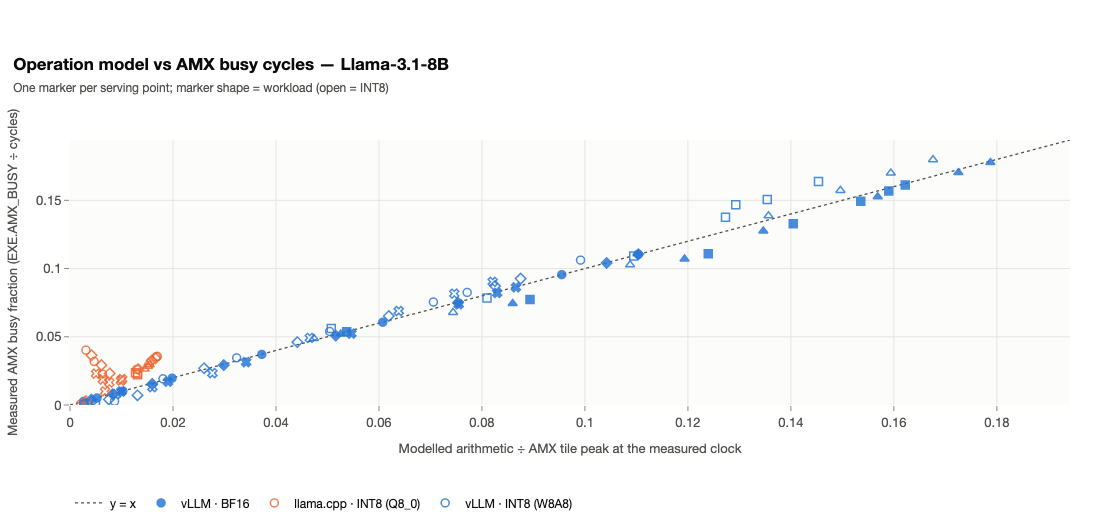

Configuration,Points,Median busy ÷ modelled,Min,Max
llama.cpp · INT8 (Q8_0),20,2.06,1.69,13.01
vLLM · BF16,28,0.99,0.87,1.00
vLLM · INT8 (W8A8),29,1.07,0.84,1.14


For vLLM the measured AMX busy fraction is 0.84–1.14 × the modelled share (median 1.00, 57 points). For llama.cpp Q8_0 it is 1.7–13.0 × (median 2.1). The highest AMX busy fraction of any point is 18%; the oneDNN GEMM roof itself is 40% of the tile peak.

In [5]:
pts_all = roofline.add_roofline_metrics(memory.add_traffic_model(loaders.online_points()), compute)
pts = pts_all[pts_all["model"] == MODEL]
amx = roofline.amx_cross_check(pts)
amx = amx[amx["configuration_id"] != "llama_cpp_bf16"]
fig = plots.parity_scatter(amx, x="modelled_amx_share", y="amx_busy_frac_mean",
                           x_title="Modelled arithmetic ÷ AMX tile peak at the measured clock",
                           y_title="Measured AMX busy fraction (EXE.AMX_BUSY ÷ cycles)",
                           title=f"Operation model vs AMX busy cycles — {registry.model_label(MODEL)}",
                           subtitle="One marker per serving point; marker shape = workload (open = INT8)")
fig.show()
export_figure(fig, "amx_model_cross_check", source=NOTEBOOK,
              caption="Modelled arithmetic as a share of the AMX tile peak vs measured AMX busy fraction, every 8B point.")
busy = amx[amx["amx_busy_frac_mean"] >= 0.02].assign(ratio=lambda d: d["amx_busy_frac_mean"] / d["modelled_amx_share"])
by = busy.groupby("configuration_id")["ratio"].describe()[["count", "50%", "min", "max"]]
display(table(by.reset_index().assign(configuration_id=lambda d: d["configuration_id"].map(registry.configuration_label))
              .rename(columns={"configuration_id": "Configuration", "count": "Points", "50%": "Median busy ÷ modelled",
                               "min": "Min", "max": "Max"}),
              {"Points": "{:.0f}", "Median busy ÷ modelled": "{:.2f}", "Min": "{:.2f}", "Max": "{:.2f}"},
              caption="Points with AMX busy ≥ 2% of cycles"))
vb = busy[busy["backend"] == "vllm"]["ratio"]
lq = busy[busy["configuration_id"] == "llama_cpp_int8"]["ratio"]
show(f"For vLLM the measured AMX busy fraction is {rng(vb, lambda v: f'{v:.2f}')} × the modelled share "
     f"(median {vb.median():.2f}, {len(vb)} points). For llama.cpp Q8_0 it is {rng(lq, lambda v: f'{v:.1f}')} × "
     f"(median {lq.median():.1f}). The highest AMX busy fraction of any point is "
     f"{pct(amx['amx_busy_frac_mean'].max(), signed=False)}; the oneDNN GEMM roof itself is "
     f"{pct(gemm / compute.loc['amx_bf16_peak', 'tops'], signed=False)} of the tile peak.")

**Interpretation.** Two independent quantities — operations derived from the token rates and the architecture, and
cycles counted by the AMX unit — agree closely for vLLM at every concurrency and workload. This validates the
arithmetic axis of the roofline (the bytes axis was validated against STREAM in notebook 01) and says that when
vLLM's AMX unit is busy, it does useful tile arithmetic at full rate. The unit is still idle most of the time, but so
it is in the GEMM benchmark that defines the compute roof: on this socket an AMX GEMM is limited by feeding the tiles
(tile loads from cache), not by tile arithmetic, which is why the measured GEMM roof is a fraction of the tile peak.
llama.cpp Q8_0 is the opposite case: its AMX unit is busy *longer* than its useful arithmetic needs — about twice as
long typically, and much more at some points — the signature of tile instructions working on mostly empty tiles
(few rows per GEMM call) rather than of a lack of AMX use.

## 3. Where each configuration sits

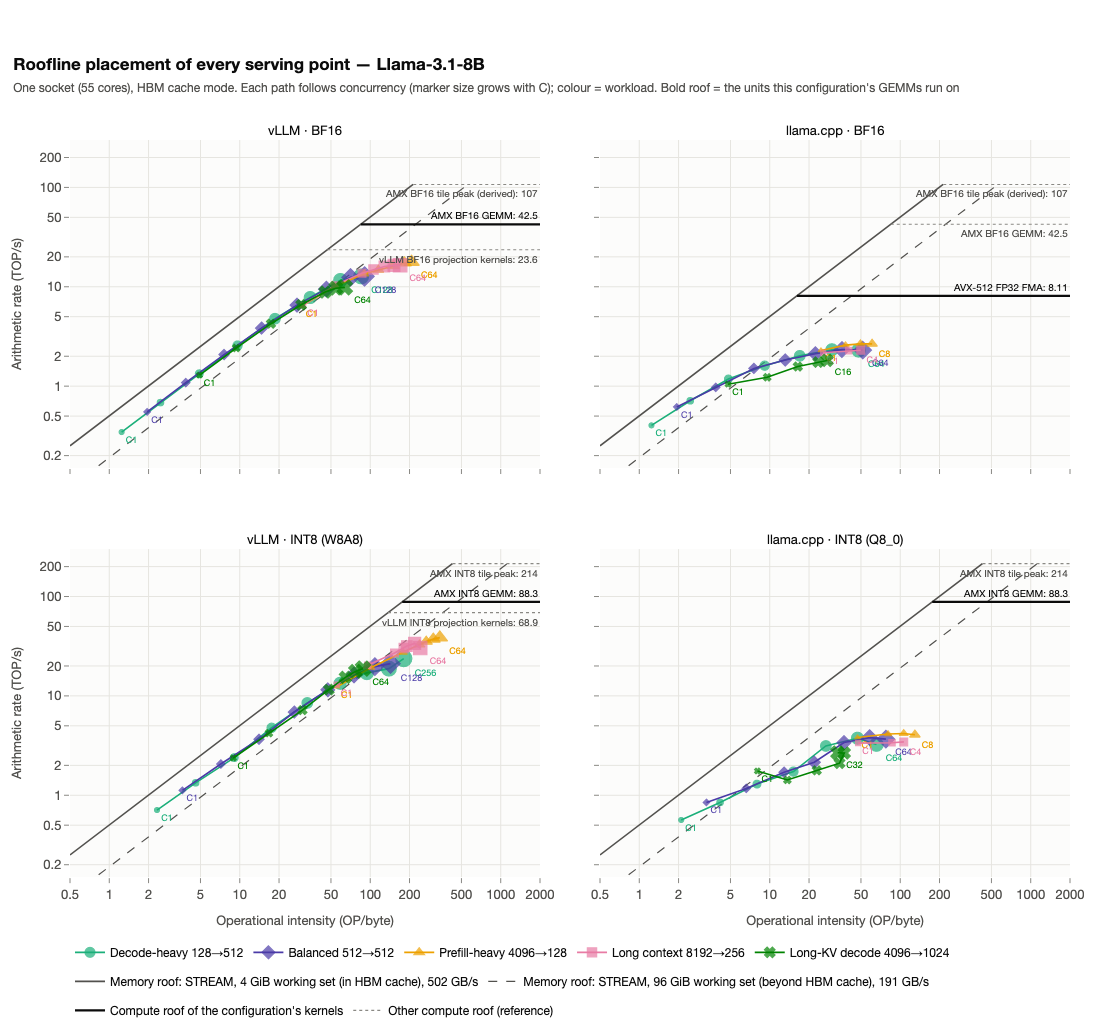

In [6]:
def roof_label(k):
    return compute.loc[k, "label"] + (" (derived)" if str(compute.loc[k, "basis"]).startswith("derived") else "")


confs = [c for c in ["vllm_bf16", "llama_cpp_bf16", "vllm_int8", "llama_cpp_int8"] if c in set(pts["configuration_id"])]
own_roofs = {c: [(compute.loc[roofline.KERNEL_CEILING[c], "tops"], roof_label(roofline.KERNEL_CEILING[c]), True)]
                + [(compute.loc[k, "tops"], roof_label(k), False) for k in roofline.CONTEXT_CEILINGS[c]] for c in confs}
fig = plots.roofline_grid(pts, facet="configuration_id", facets=confs, cols=2, trace_key="workload", roofs=own_roofs,
                          memory=memory_roofs, title=f"Roofline placement of every serving point — {registry.model_label(MODEL)}",
                          subtitle=f"One socket ({cores} cores), HBM cache mode. Each path follows concurrency (marker size grows "
                                   "with C); colour = workload. Bold roof = the units this configuration's GEMMs run on")
fig.show()
export_figure(fig, "roofline_by_configuration", source=NOTEBOOK,
              caption="Roofline of every 8B serving point per configuration, with measured memory roofs (STREAM in and "
                      "beyond the HBM cache) and the compute roof of each configuration's kernels.")

In [7]:
cross = roofline.regime_crossings(pts)
cross = cross.assign(configuration=cross["configuration_id"].map(registry.configuration_label),
                     workload_s=cross["workload"].map(lambda w: registry.workload_label(w, short=True)))
display(table(cross[["configuration", "workload_s", "c_first", "intensity_first", "bw_util_first", "c_last", "intensity_last",
                     "ridge_last", "op_rate_max", "compute_util_max", "c_cross"]]
              .rename(columns={"configuration": "Configuration", "workload_s": "Workload", "c_first": "C min",
                               "intensity_first": "OP/byte at C min", "bw_util_first": "share of memory roof at C min",
                               "c_last": "C max", "intensity_last": "OP/byte at C max", "ridge_last": "ridge at C max",
                               "op_rate_max": "best TOP/s", "compute_util_max": "best share of compute roof",
                               "c_cross": "first C on compute side"}),
              {"OP/byte at C min": "{:.1f}", "share of memory roof at C min": "{:.0%}", "OP/byte at C max": "{:.0f}",
               "ridge at C max": "{:.0f}", "best TOP/s": "{:.1f}", "best share of compute roof": "{:.0%}",
               "first C on compute side": "{:.0f}"},
              caption=f"Regime per curve, {registry.model_label(MODEL)} ('–': never crosses the ridge)"))
c1 = pts[pts["concurrency"] == 1]
dec1 = c1[c1["isl"] <= c1["osl"]]
best = pts.loc[pts.groupby("configuration_id")["compute_utilization"].idxmax()].set_index("configuration_id")
show(f"At C = 1, the short-prompt shapes (ISL ≤ OSL) of every configuration are on the memory-bound side and use "
     f"{rng(dec1['bw_utilization'], lambda v: pct(v, signed=False))} of the memory roof. Best share of the compute roof per "
     "configuration: " + "; ".join(f"{registry.configuration_label(c)} {pct(best.loc[c, 'compute_utilization'], signed=False)} "
                                    f"({num(best.loc[c, 'op_rate_tops'], 1)} TOP/s, {best.loc[c, 'workload_shape']}, "
                                    f"C = {best.loc[c, 'concurrency']})" for c in confs) + ".")

Configuration,Workload,C min,OP/byte at C min,share of memory roof at C min,C max,OP/byte at C max,ridge at C max,best TOP/s,best share of compute roof,first C on compute side
vLLM · BF16,128→512,1,1.2,58%,128,85,95,12.7,30%,–
llama.cpp · BF16,128→512,1,1.2,67%,64,48,17,2.3,29%,16
llama.cpp · INT8 (Q8_0),128→512,1,2.1,54%,64,66,180,3.8,4%,–
vLLM · INT8 (W8A8),128→512,1,2.3,62%,256,181,196,23.8,27%,–
vLLM · BF16,512→512,1,2.0,59%,128,90,103,12.7,30%,–
llama.cpp · BF16,512→512,1,1.9,66%,64,52,18,2.3,29%,16
llama.cpp · INT8 (Q8_0),512→512,1,3.3,52%,64,78,183,3.8,4%,–
vLLM · INT8 (W8A8),512→512,1,3.6,62%,128,143,196,21.1,24%,–
vLLM · BF16,4096→128,1,29.8,45%,64,207,138,17.8,42%,4
llama.cpp · BF16,4096→128,1,24.7,19%,8,61,18,2.7,33%,1


At C = 1, the short-prompt shapes (ISL ≤ OSL) of every configuration are on the memory-bound side and use 52%–67% of the memory roof. Best share of the compute roof per configuration: vLLM · BF16 42% (17.8 TOP/s, 4096→128, C = 64); llama.cpp · BF16 33% (2.7 TOP/s, 4096→128, C = 4); vLLM · INT8 (W8A8) 44% (38.6 TOP/s, 4096→128, C = 64); llama.cpp · INT8 (Q8_0) 5% (4.2 TOP/s, 4096→128, C = 4).

**Interpretation.**
- **Low-concurrency decode is memory-bound for everyone.** A single decode stream reads all weights per token, so
  the intensity is a few operations per byte and every configuration runs on the memory roof's slope, at roughly half
  to two thirds of the STREAM bandwidth. INT8 halves the weight bytes and so doubles the intensity at C = 1; it does
  not change the regime. Long prompts are the exception: one prefill is already a large GEMM (section 4).
- **vLLM climbs the memory roof towards the ridge.** Each doubling of C roughly doubles the intensity (the weight
  read is shared by twice the tokens) and the arithmetic rate with it, so vLLM's paths run parallel to the memory roof.
  The long-prompt shapes, whose prefill chunks are already large GEMMs, cross the ridge with a few requests; the
  decode-heavy shapes reach it only at the highest concurrency. At their best, vLLM's points use a bit less than half
  of the best measured GEMM roof, but more than half of what vLLM's own projection kernels allow on these shapes (three
  quarters at BF16; the third roof in the vLLM panels). So vLLM is bounded first by memory, then mainly by how efficiently its kernels handle the Llama
  shapes — above all the BF16 gate_up GEMM — rather than by the AMX hardware.
- **llama.cpp stalls below both roofs.** Its intensity also rises with C, but its arithmetic rate flattens at a
  level well below its own compute roof (AVX-512 at BF16, AMX INT8 at Q8_0) while its traffic falls far below the
  memory roof. Neither hardware roof binds: the limit is in the engine (per-sequence attention, small-batch kernel
  shapes, the AVX-512 BF16 dot-product path without AMX), which is the roofline view of the scaling plateau of
  notebook 04 and the step-cost growth of notebook 06.

## 4. Head to head, by workload and context length

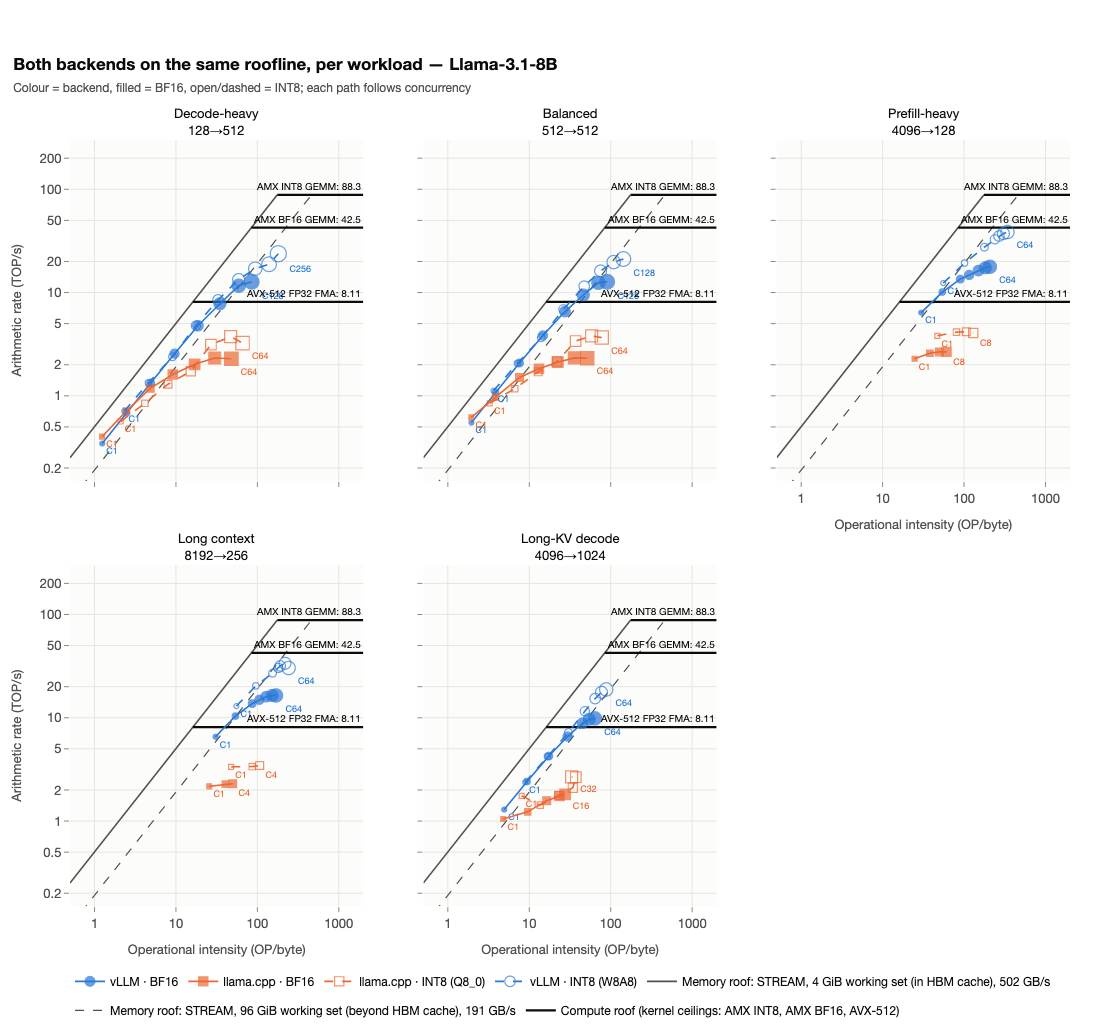

In [8]:
pair_roofs = [(compute.loc[k, "tops"], roof_label(k), True) for k in ["amx_int8_gemm", "amx_bf16_gemm", "avx512_fma"]]
wls = [w for w in registry.workload_order() if w in set(pts["workload"])]
fig = plots.roofline_grid(pts, facet="workload", facets=wls, cols=3, trace_key="configuration_id",
                          roofs={w: pair_roofs for w in wls}, memory=memory_roofs,
                          compute_legend=("Compute roof (kernel ceilings: AMX INT8, AMX BF16, AVX-512)",),
                          title=f"Both backends on the same roofline, per workload — {registry.model_label(MODEL)}",
                          subtitle="Colour = backend, filled = BF16, open/dashed = INT8; each path follows concurrency")
fig.show()
export_figure(fig, "roofline_by_workload", source=NOTEBOOK,
              caption="vLLM and llama.cpp (BF16 and INT8) on one roofline per workload, 8B, paths over concurrency.")

In [9]:
def at(cid, wl, c):
    r = pts[(pts["configuration_id"] == cid) & (pts["workload"] == wl) & (pts["concurrency"] == c)]
    return r.iloc[0] if len(r) else None


rows = []
for cid in confs:
    for wl in wls:
        for c in (1, 4):
            r = at(cid, wl, c)
            if r is not None:
                rows.append({"configuration": registry.configuration_label(cid), "C": c, "workload": r["workload_shape"],
                             "mean context": r["isl"] + r["osl"] / 2, "prefill share of ops": r["prefill_op_share"],
                             "OP/byte": r["intensity"], "TOP/s": r["op_rate_tops"], "regime": r["regime"]})
ctx = pd.DataFrame(rows).sort_values(["configuration", "C", "mean context"], kind="stable")
display(table(ctx, {"mean context": "{:.0f}", "prefill share of ops": "{:.0%}", "OP/byte": "{:.1f}", "TOP/s": "{:.2f}"},
              caption="The same concurrency across workloads (C = 1 and C = 4, measured for every configuration and workload)"))

configuration,C,workload,mean context,prefill share of ops,OP/byte,TOP/s,regime
llama.cpp · BF16,1,128→512,384,19%,1.2,0.40,memory-bound side
llama.cpp · BF16,1,512→512,768,48%,1.9,0.62,memory-bound side
llama.cpp · BF16,1,4096→128,4160,97%,24.7,2.29,compute-bound side
llama.cpp · BF16,1,4096→1024,4608,78%,4.8,1.05,memory-bound side
llama.cpp · BF16,1,8192→256,8320,96%,25.6,2.17,compute-bound side
llama.cpp · BF16,4,128→512,384,19%,4.8,1.18,memory-bound side
llama.cpp · BF16,4,512→512,768,48%,7.6,1.51,memory-bound side
llama.cpp · BF16,4,4096→128,4160,97%,49.5,2.66,compute-bound side
llama.cpp · BF16,4,4096→1024,4608,78%,16.4,1.58,memory-bound side
llama.cpp · BF16,4,8192→256,8320,96%,49.8,2.30,compute-bound side


**Interpretation.** At fixed concurrency, *where the context comes from* decides the placement. A long prompt is
processed as one prefill — a large GEMM over thousands of tokens — so prefill-heavy and long-context shapes start far
to the right (tens of operations per byte at C = 1) and vLLM reaches the ridge with a handful of requests. A
long context that is *decoded over* (4096→1024) is the opposite case: each output token re-reads its whole KV cache,
the intensity grows more slowly with C than in the short-context shapes, and vLLM BF16 never crosses the ridge in
this shape. Between the backends the vertical gap is the story: it is small for single-request decode, already
large for single long prompts, and it opens with concurrency, because llama.cpp's paths flatten while vLLM's keep rising
towards a higher roof (AMX).

## 5. How concurrency moves the points across the ridge

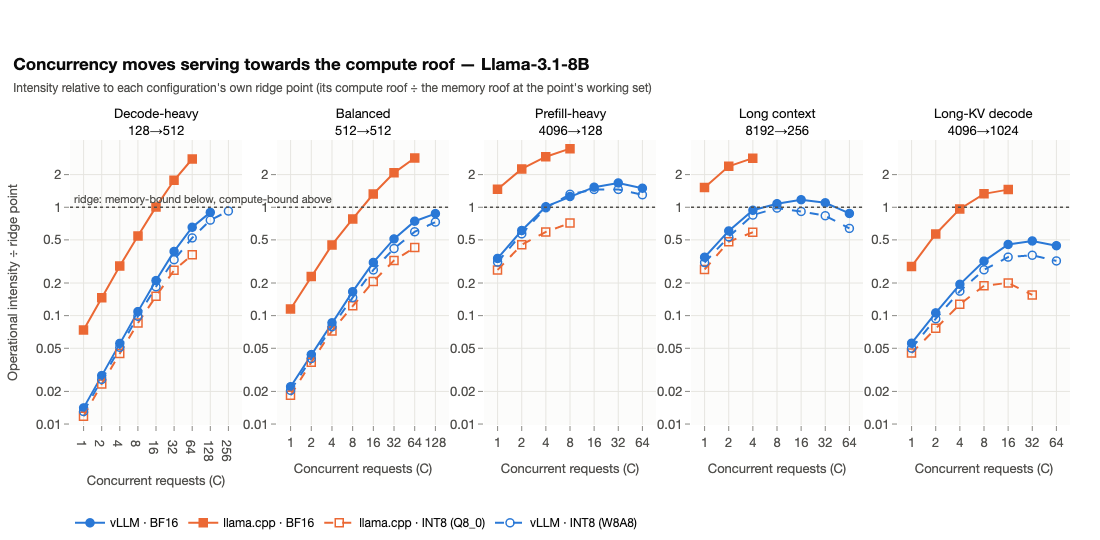

vLLM share of the memory roof from C = 16 to the highest C, long-context shapes: vLLM · BF16 4096→1024 46% → 52%; vLLM · BF16 8192→256 32% → 44%; vLLM · INT8 (W8A8) 4096→1024 50% → 67%; vLLM · INT8 (W8A8) 8192→256 39% → 54%.

Long-KV decode at the highest C: vLLM · BF16 C = 64: working set 50 GiB, memory roof 294 GB/s, intensity ÷ ridge 0.44, share of memory roof 52%; vLLM · INT8 (W8A8) C = 64: working set 43 GiB, memory roof 321 GB/s, intensity ÷ ridge 0.32, share of memory roof 67%.

In [10]:
fig = plots.concurrency_lines(pts, plots.Panel("ridge_ratio", "Operational intensity ÷ ridge point", "×", log_y=True,
                                               error=None, share_y=True, fmt=".2f",
                                               reference=(1, "ridge: memory-bound below, compute-bound above")),
                              title=f"Concurrency moves serving towards the compute roof — {registry.model_label(MODEL)}",
                              subtitle="Intensity relative to each configuration's own ridge point (its compute roof ÷ the "
                                       "memory roof at the point's working set)")
fig.show()
export_figure(fig, "ridge_ratio_vs_concurrency", source=NOTEBOOK,
              caption="Operational intensity divided by each configuration's ridge point vs concurrency (8B); above 1 = compute-bound side.")
kv = pts[(pts["workload"] == "kvdecode") & (pts["backend"] == "vllm")]
kvlast = kv.loc[kv.groupby("configuration_id")["concurrency"].idxmax()].set_index("configuration_id")
late = pts[(pts["backend"] == "vllm") & pts["workload"].isin(["longctx", "kvdecode"]) & (pts["concurrency"] >= 16)]
share = late.pivot_table(index=["configuration_id", "workload"], columns="concurrency", values="bw_utilization")
show("vLLM share of the memory roof from C = 16 to the highest C, long-context shapes: " + "; ".join(
    f"{registry.configuration_label(c)} {registry.workload_label(w, short=True)} "
    f"{pct(r.dropna().iloc[0], signed=False)} → {pct(r.dropna().iloc[-1], signed=False)}" for (c, w), r in share.iterrows()) + ".")
show("Long-KV decode at the highest C: " + "; ".join(
    f"{registry.configuration_label(c)} C = {kvlast.loc[c, 'concurrency']}: working set "
    f"{num(kvlast.loc[c, 'working_set_gib_model'])} GiB, memory roof {num(kvlast.loc[c, 'memory_roof_gbs'])} GB/s, "
    f"intensity ÷ ridge {kvlast.loc[c, 'ridge_ratio']:.2f}, share of memory roof "
    f"{pct(kvlast.loc[c, 'bw_utilization'], signed=False)}" for c in kvlast.index) + ".")

**Interpretation.** At low and moderate concurrency the ratio grows with C on every curve — concurrency pushes
serving towards compute — at rates that differ by configuration and shape (llama.cpp BF16 sits highest only because its
AVX-512 roof makes its ridge low). At high C a second effect takes over in the long-context shapes: the KV cache grows
with C, the working set leaves the comfortable part of the HBM cache, the memory roof falls (section 1) and the ridge
moves right, so the ratio *falls* again (vLLM prefill-heavy, long context and long-KV decode) and long-KV decode never
reaches the compute side. There, more concurrency brings vLLM back towards the memory roof — the regime where the HBM
cache, and its capacity, matter.

## 6. What limits each point: share of the memory roof vs share of the compute roof

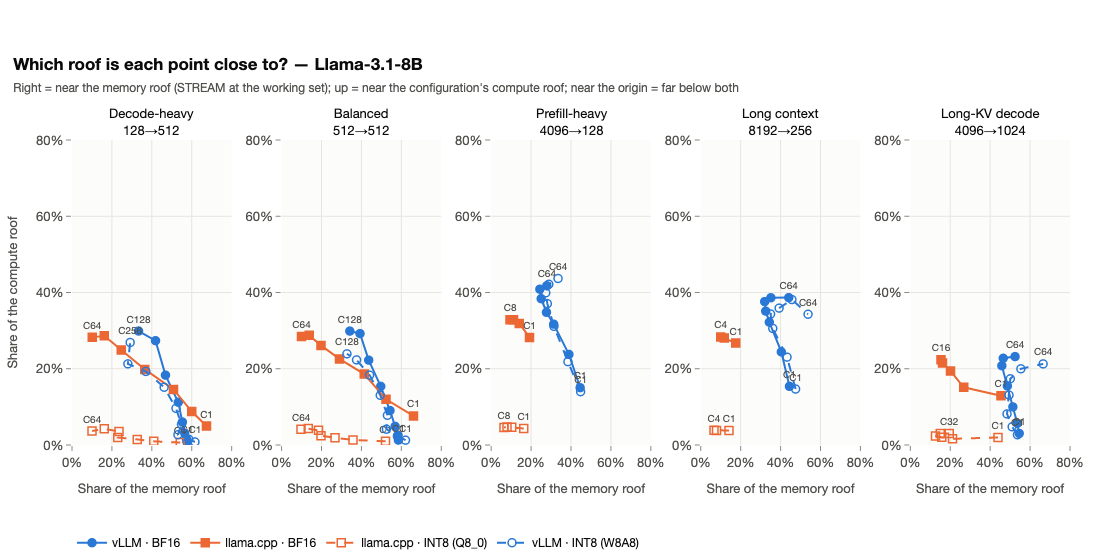

configuration,compute roof,roof TOP/s,offline engine best TOP/s,online best TOP/s,engine kernels TOP/s,offline ÷ roof,online ÷ engine kernels,online ÷ offline
vLLM · BF16,AMX BF16 GEMM,42.5,20.3,17.8,23.6,48%,75%,88%
llama.cpp · BF16,AVX-512 FP32 FMA,8.1,3.4,2.7,–,41%,–,79%
vLLM · INT8 (W8A8),AMX INT8 GEMM,88.3,49.5,38.6,68.9,56%,56%,78%
llama.cpp · INT8 (Q8_0),AMX INT8 GEMM,88.3,8.9,4.2,–,10%,–,47%


Offline engine best ÷ compute roof: vLLM · BF16 48%; llama.cpp · BF16 41%; vLLM · INT8 (W8A8) 56%; llama.cpp · INT8 (Q8_0) 10%. Online best ÷ offline best: vLLM · BF16 88%; llama.cpp · BF16 79%; vLLM · INT8 (W8A8) 78%; llama.cpp · INT8 (Q8_0) 47%. vLLM online best ÷ its projection kernels: vLLM · BF16 75%; vLLM · INT8 (W8A8) 56%.

In [11]:
fig = plots.path_scatter(pts, x="bw_utilization", y="compute_utilization", x_title="Share of the memory roof",
                         y_title="Share of the compute roof", label_cs=(1,), x_scale=1, y_scale=1,
                         title=f"Which roof is each point close to? — {registry.model_label(MODEL)}",
                         subtitle="Right = near the memory roof (STREAM at the working set); up = near the configuration's "
                                  "compute roof; near the origin = far below both", height=560)
fig.update_xaxes(range=[0, 0.8], tickformat=".0%", dtick=0.2)
fig.update_yaxes(range=[0, 0.8], tickformat=".0%", dtick=0.2)
fig.show()
export_figure(fig, "roofline_utilization", source=NOTEBOOK,
              caption="Share of the memory roof vs share of the compute roof for every 8B point, paths over concurrency.")
eng = roofline.engine_ceilings(loaders.offline_samples(model=MODEL)).set_index("configuration_id")
online_best = pts.groupby("configuration_id")["op_rate_tops"].max()
lim = pd.DataFrame({"configuration": [registry.configuration_label(c) for c in confs],
                    "compute roof": [roof_label(roofline.KERNEL_CEILING[c]) for c in confs],
                    "roof TOP/s": [compute.loc[roofline.KERNEL_CEILING[c], "tops"] for c in confs],
                    "offline engine best TOP/s": [eng["op_rate_tops"].get(c, np.nan) for c in confs],
                    "online best TOP/s": [online_best[c] for c in confs]})
lim["engine kernels TOP/s"] = [compute["tops"].get(f"{c}_kernels", np.nan) for c in confs]
lim["offline ÷ roof"] = lim["offline engine best TOP/s"] / lim["roof TOP/s"]
lim["online ÷ engine kernels"] = lim["online best TOP/s"] / lim["engine kernels TOP/s"]
lim["online ÷ offline"] = lim["online best TOP/s"] / lim["offline engine best TOP/s"]
display(table(lim, {"roof TOP/s": "{:.1f}", "offline engine best TOP/s": "{:.1f}", "online best TOP/s": "{:.1f}",
                    "engine kernels TOP/s": "{:.1f}", "offline ÷ roof": "{:.0%}", "online ÷ offline": "{:.0%}",
                    "online ÷ engine kernels": "{:.0%}"},
              caption="Hardware roof, the best arithmetic rate each engine reaches offline (any prefill benchmark), and online"))
lb = lim.set_index("configuration")
show("Offline engine best ÷ compute roof: " + "; ".join(f"{c} {pct(v, signed=False)}" for c, v in lb["offline ÷ roof"].items())
     + ". Online best ÷ offline best: " + "; ".join(f"{c} {pct(v, signed=False)}" for c, v in lb["online ÷ offline"].items())
     + ". vLLM online best ÷ its projection kernels: " + "; ".join(f"{c} {pct(v, signed=False)}" for c, v
                                                                  in lb["online ÷ engine kernels"].dropna().items()) + ".")

**Interpretation.** At low C every configuration sits on the right (memory roof) at about the same share; with C the
vLLM paths curve upwards towards the compute roof while their memory share falls, and llama.cpp's paths fall towards
the origin — away from *both* roofs. The engine benchmarks of notebook 02 agree: even offline, with no server in the
way, llama.cpp's kernels reach only part of its own compute roof (and Q8_0 a small part of the AMX INT8 roof), and
online it loses a further share to serving. llama.cpp's limit is its kernels and batching, not the socket. vLLM's
offline peak is about half of the hardware GEMM roof and most of what its projection kernels allow on the Llama
shapes, and its server keeps most of that online. The remaining gap to the hardware roof lies in the kernels (shape-dependent
GEMM efficiency), not in serving.

## 7. Context length: why long-context decode stays memory-bound

A decode step of B sequences with context L reads the weights once and each sequence's KV cache, so its minimum-traffic
intensity is B × ops per token ÷ (weight bytes + B × L × KV bytes per token). Batching removes the weight term but not
the KV term: for large B the intensity tends to ops per token ÷ (L × KV bytes per token), whatever the concurrency.

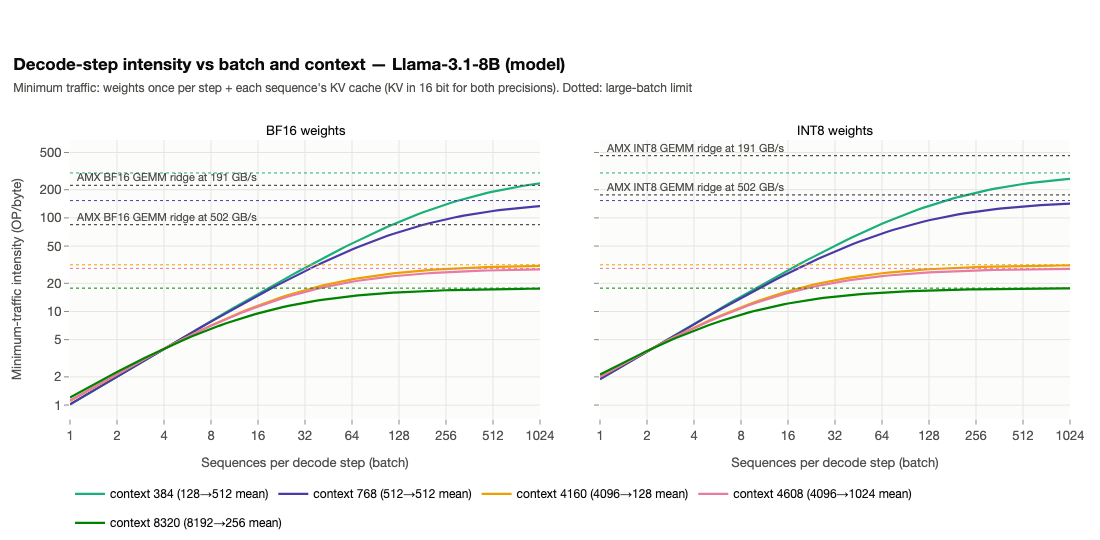

Large-batch limit of the decode intensity: 18–302 OP/byte over the measured contexts (384, 768, 4160, 4608, 8320). It equals the AMX BF16 GEMM ridge in the HBM cache (85 OP/byte) at a context of about 1,419 tokens: beyond that, decode cannot become compute-bound on AMX at any batch size.

In [12]:
arch = roofline.architecture(MODEL)
mcfg = registry.experiment_config()["models"][MODEL]
kvb = mcfg["kv_bytes_per_token"]
wl_ctx = registry.workloads().assign(context=lambda d: d["isl"] + d["osl"] / 2).sort_values("context")
batch = np.unique(np.round(np.logspace(0, 10, 81, base=2)))
curves, limits = [], []
precisions = {"BF16 weights": ("bf16", "amx_bf16_gemm"), "INT8 weights": ("w8a8", "amx_int8_gemm")}
for panel, (prec, _) in precisions.items():
    wbytes = registry.step_weight_bytes(MODEL, prec)
    for r in wl_ctx.itertuples():
        label = f"context {r.context:.0f} ({registry.workload_label(r.workload, short=True)} mean)"
        curves.append(pd.DataFrame({"panel": panel, "context": r.context, "context_label": label, "batch": batch,
                                    "intensity": roofline.decode_step_intensity(arch, wbytes, kvb, batch, r.context)}))
        limits.append({"panel": panel, "context": r.context, "limit": roofline.decode_intensity_limit(arch, kvb, r.context)})
curves, limits = pd.concat(curves, ignore_index=True), pd.DataFrame(limits)
ridges = {panel: [(compute.loc[k, "tops"] * 1e3 / gbs, f"{roof_label(k)} ridge at {gbs:.0f} GB/s")
                  for gbs, _ in memory_roofs] for panel, (_, k) in precisions.items()}
fig = plots.intensity_model_curves(curves, facet="panel", ridges=ridges, limits=limits,
                                   title=f"Decode-step intensity vs batch and context — {registry.model_label(MODEL)} (model)",
                                   subtitle="Minimum traffic: weights once per step + each sequence's KV cache (KV in 16 bit "
                                            "for both precisions). Dotted: large-batch limit")
fig.show()
export_figure(fig, "decode_intensity_limit", source=NOTEBOOK,
              caption="Modelled decode-step intensity vs batch for the measured mean contexts, with AMX ridge points, 8B.")
lim_tab = limits.pivot(index="context", columns="panel", values="limit").reset_index()
bf16_ridge = ridges["BF16 weights"][0][0]
crit_ctx = (arch.linear_ops + arch.logits_ops) / (bf16_ridge * kvb - arch.attention_ops_per_position)
show(f"Large-batch limit of the decode intensity: {rng(limits['limit'], lambda v: f'{v:.0f}')} OP/byte over the measured "
     f"contexts ({', '.join(f'{c:.0f}' for c in lim_tab['context'])}). It equals the AMX BF16 GEMM ridge in the HBM cache "
     f"({bf16_ridge:.0f} OP/byte) at a context of about {num(crit_ctx)} tokens: beyond that, decode cannot become "
     "compute-bound on AMX at any batch size.")

**Interpretation.** For the short contexts the large-batch limit lies far above the ridge, so batching alone can make
decode compute-bound — vLLM approaches that at its highest C. For the 4096-token contexts the limit is far below the
AMX ridge in the HBM cache: decode over long contexts stays memory-bound however many sequences are batched, and every
extra sequence adds its own KV stream. INT8 weights do not help here — the KV cache is still 16-bit, and the INT8
ridge is twice as far to the right. Measured long-KV decode (section 5) follows this picture. This is the regime
the thesis's HBM studies should target: concurrent decode over long or growing KV caches.

## 8. Cross-check: Llama-3.2-1B

In [13]:
small = pts_all[pts_all["model"] != MODEL]
if small.empty:
    show("No cross-check model in the primary campaign.")
else:
    cr1 = roofline.regime_crossings(small)
    cr1 = cr1.assign(configuration=cr1["configuration_id"].map(registry.configuration_label),
                     workload_s=cr1["workload"].map(lambda w: registry.workload_label(w, short=True)))
    display(table(cr1[["configuration", "workload_s", "c_first", "bw_util_first", "c_last", "intensity_last", "ridge_last",
                       "op_rate_max", "compute_util_max", "c_cross"]]
                  .rename(columns={"configuration": "Configuration", "workload_s": "Workload", "c_first": "C min",
                                   "bw_util_first": "share of memory roof at C min", "c_last": "C max",
                                   "intensity_last": "OP/byte at C max", "ridge_last": "ridge at C max",
                                   "op_rate_max": "best TOP/s", "compute_util_max": "best share of compute roof",
                                   "c_cross": "first C on compute side"}),
                  {"share of memory roof at C min": "{:.0%}", "OP/byte at C max": "{:.0f}", "ridge at C max": "{:.0f}",
                   "best TOP/s": "{:.2f}", "best share of compute roof": "{:.0%}", "first C on compute side": "{:.0f}"},
                  caption=f"Regime per curve, {registry.model_label(small['model'].iloc[0])}"))
    b1 = small.groupby("backend")["compute_utilization"].max()
    show("Best share of the compute roof, 1B: " + "; ".join(f"{registry.backend_label(b)} {pct(v, signed=False)}"
                                                           for b, v in b1.items()) + ".")

Configuration,Workload,C min,share of memory roof at C min,C max,OP/byte at C max,ridge at C max,best TOP/s,best share of compute roof,first C on compute side
vLLM · BF16,128→512,1,40%,256,106,85,10.76,25%,256
llama.cpp · BF16,128→512,1,52%,64,43,16,1.17,14%,32
llama.cpp · INT8 (Q8_0),128→512,1,44%,64,53,176,1.76,2%,–
vLLM · BF16,512→512,1,40%,256,91,86,11.80,28%,256
llama.cpp · BF16,512→512,1,48%,64,50,16,1.45,18%,16
llama.cpp · INT8 (Q8_0),512→512,1,42%,64,59,176,2.09,2%,–
vLLM · BF16,4096→128,1,34%,64,154,87,16.80,40%,8
llama.cpp · BF16,4096→128,1,14%,8,72,16,2.10,26%,1
llama.cpp · INT8 (Q8_0),4096→128,1,13%,8,100,176,3.31,4%,–


Best share of the compute roof, 1B: llama.cpp 26%; vLLM 40%.

**Interpretation.** With 1B parameters each token carries several times less arithmetic and the fixed per-step
costs of the engine weigh more, so both backends stay further from the compute roof than with 8B; the ordering — vLLM rising towards
its roof, llama.cpp flattening below both — is the same, so it belongs to the backends, not to one model size.

## 9. Claims checked against the data

In [14]:
bf = cross[cross["configuration_id"] == "vllm_bf16"].set_index("workload")
ll = pts[pts["backend"] == "llama_cpp"]
ll_late = ll[ll["concurrency"] >= 8]
v_best = pts[pts["backend"] == "vllm"].groupby("configuration_id")["compute_utilization"].max()
kv_lim = limits[(limits["panel"] == "BF16 weights")].set_index("context")["limit"]
kv_ctx = registry.workloads().set_index("workload").loc["kvdecode"]
kv_ctx = kv_ctx["isl"] + kv_ctx["osl"] / 2
claims = [
    Claim("At C = 1 every configuration's short-prompt shapes (ISL ≤ OSL) are memory-bound and use ≥ 50% of the memory roof",
          bool((dec1["regime"] == "memory-bound side").all() and (dec1["bw_utilization"] >= 0.5).all()),
          rng(dec1["bw_utilization"], lambda v: pct(v, signed=False))),
    Claim("The operation model agrees with vLLM's AMX busy cycles within ±25% (points with AMX busy ≥ 2%)",
          bool(((vb - 1).abs() <= 0.25).all()), rng(vb, lambda v: f"{v:.2f}")),
    Claim("vLLM BF16 crosses the ridge in the long-prompt shapes (4096→128, 8192→256) and in no decode-dominated shape",
          bool(bf[bf.index.isin(["prefill", "longctx"])]["c_cross"].notna().all()
               and bf[bf.index.isin(["decode", "balanced", "kvdecode"])]["c_cross"].isna().all()),
          ", ".join(f"{registry.workload_label(w, short=True)}: C={'–' if np.isnan(v) else int(v)}" for w, v in bf["c_cross"].items())),
    Claim("vLLM's best point reaches ≥ 40% of the measured GEMM roof in both precisions",
          bool((v_best >= 0.4).all()), ", ".join(f"{registry.configuration_label(c)} {pct(v, signed=False)}" for c, v in v_best.items())),
    Claim("vLLM's best online point reaches ≥ 50% of its own projection kernels' ceiling in both precisions",
          bool((lb["online ÷ engine kernels"].dropna() >= 0.5).all()),
          ", ".join(f"{c} {pct(v, signed=False)}" for c, v in lb["online ÷ engine kernels"].dropna().items())),
    Claim("vLLM's BF16 projection kernels reach < 60% of the BF16 GEMM roof on the Llama shapes",
          bool(compute.loc["vllm_bf16_kernels", "tops"] / compute.loc["amx_bf16_gemm", "tops"] < 0.6),
          pct(compute.loc["vllm_bf16_kernels", "tops"] / compute.loc["amx_bf16_gemm", "tops"], signed=False)),
    Claim("No llama.cpp point reaches 40% of its compute roof",
          bool(ll["compute_utilization"].max() < 0.4), f"max {pct(ll['compute_utilization'].max(), signed=False)}"),
    Claim("From C = 8 on, llama.cpp uses < 40% of the memory roof (below both roofs)",
          bool(ll_late["bw_utilization"].max() < 0.4), f"max {pct(ll_late['bw_utilization'].max(), signed=False)}"),
    Claim("For long-KV decode contexts the large-batch decode intensity is below the AMX BF16 ridge in the HBM cache",
          bool(kv_lim.loc[kv_ctx] < bf16_ridge), f"{kv_lim.loc[kv_ctx]:.0f} vs {bf16_ridge:.0f} OP/byte"),
]
display(claims_table(claims))

Holds,Statement,Evidence (computed)
✓,At C = 1 every configuration's short-prompt shapes (ISL ≤ OSL) are memory-bound and use ≥ 50% of the memory roof,52%–67%
✓,The operation model agrees with vLLM's AMX busy cycles within ±25% (points with AMX busy ≥ 2%),0.84–1.14
✓,"vLLM BF16 crosses the ridge in the long-prompt shapes (4096→128, 8192→256) and in no decode-dominated shape","128→512: C=–, 512→512: C=–, 4096→128: C=4, 8192→256: C=8, 4096→1024: C=–"
✓,vLLM's best point reaches ≥ 40% of the measured GEMM roof in both precisions,"vLLM · BF16 42%, vLLM · INT8 (W8A8) 44%"
✓,vLLM's best online point reaches ≥ 50% of its own projection kernels' ceiling in both precisions,"vLLM · BF16 75%, vLLM · INT8 (W8A8) 56%"
✓,vLLM's BF16 projection kernels reach < 60% of the BF16 GEMM roof on the Llama shapes,55%
✓,No llama.cpp point reaches 40% of its compute roof,max 33%
✓,"From C = 8 on, llama.cpp uses < 40% of the memory roof (below both roofs)",max 36%
✓,For long-KV decode contexts the large-batch decode intensity is below the AMX BF16 ridge in the HBM cache,29 vs 85 OP/byte


In [15]:
export_cols = ["model", "configuration_id", "workload", "isl", "osl", "concurrency", "total_tok_s_mean", "op_rate_tops",
               "mem_total_gbs_mean", "intensity", "intensity_min_traffic", "working_set_gib_model", "memory_roof_gbs",
               "kernel_ceiling", "compute_roof_tops", "compute_roof_basis", "ridge_intensity", "ridge_ratio",
               "bw_utilization", "compute_utilization", "roof_efficiency", "regime", "amx_busy_frac_mean"]
export_table(pts_all[export_cols], "roofline_points")
export_table(compute.reset_index()[["ceiling", "label", "basis", "tops", "tops_measured_socket", "measured_threads",
                                    "n_records", "kernel"]], "roofline_compute_ceilings")

## Conclusions

- **Measured:** on one Xeon Max socket in HBM cache mode, every configuration starts memory-bound (single-request
  decode streams the weights at roughly half to two thirds of the STREAM bandwidth). With concurrency, vLLM's points
  climb parallel to the memory roof; long-prompt shapes cross the ridge, decode-heavy shapes reach it only at the
  highest C. vLLM's best points use somewhat less than half of the best measured AMX GEMM, and more than half of what
  its own projection kernels achieve on the Llama shapes. llama.cpp's points stop well below both roofs. Long-context decode keeps even vLLM on the memory-bound
  side, and there, as the KV cache outgrows the comfortable part of the HBM cache, the memory roof itself drops.
- **Interpretation:** vLLM is limited by memory first and then by the efficiency of its GEMM kernels on the model's
  shapes (at BF16 one oneDNN GEMM, gate_up, costs half of the AMX GEMM roof); llama.cpp is limited by its own kernels
  and batching far below both roofs. The roofline thus explains the throughput results of notebooks 04–06 instead of
  just repeating them: vLLM uses a large part of the socket and has identifiable kernel headroom, llama.cpp leaves
  most of the socket unused.
- **Implication for the thesis:** the HBM-sensitive regime is memory-bound serving: low-concurrency decode (weight
  streaming) and, above all, concurrent decode over long KV caches, where batching cannot raise the intensity and the
  working set approaches the HBM-cache capacity. vLLM is the backend that runs on the memory roof in these regimes and
  close to its kernels' limits elsewhere, so it can expose HBM/DDR effects instead of hiding them behind engine
  overheads.

## Limitations

- The arithmetic is modelled, not counted. The AMX busy-cycle check (section 2) validates it for the AMX paths;
  for llama.cpp BF16 (no AMX) it rests on the architecture and token counts alone.
- One memory level: in cache mode the counters cannot separate HBM-cache hits from DDR; the working-set-dependent
  STREAM roof is the best available proxy. Flat-mode runs or uncore counters would split the roof into HBM and DDR.
- The GEMM roofs are the best measured GEMMs (3 repetitions per shape and binding, one node), not proven maxima; the
  instruction peaks come from another node of the same partition at 56 threads. The gate_up explanation (weight larger
  than L3) is an inference from the shapes, not a measured traffic count.
- Engine-internal traffic (e.g. activation spills) is part of the measured bytes: the intensity is the engine's
  effective intensity, which is below the minimum-traffic model (`intensity_min_traffic`) where prefill dominates.